<a href="https://colab.research.google.com/github/yan434/Analise-Vendas-Python/blob/main/Exercicio_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Manipulação de dados (DataFrames)
import pandas as pd
# Operações numéricas e vetoriais
import numpy as np
# Visualizações básicas e avançadas
import matplotlib.pyplot as plt
# Gráficos estatísticos com estilo
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from google.colab import files
uploaded = files.upload()


Saving dados_vendas_empresa1_VIZ.xlsx to dados_vendas_empresa1_VIZ.xlsx


In [11]:
df = pd.read_excel('dados_vendas_empresa1_VIZ.xlsx')

In [15]:
df = pd.read_csv('dados_vendas_empresa_gerado.csv')

In [16]:
print(df.head())

   data_venda          nome_cliente estado    nome_produto    categoria  \
0  2025-05-11   Dra, Mariana da Paz     BA           Leite    Alimentos   
1  2025-03-14       Marcela Rezende     BA          Feijão    Alimentos   
2  2025-04-18    Srta, Brenda Cunha     BA   Quebra-Cabeça   Brinquedos   
3  2025-02-09  Maria Clara Caldeira     BA  Fone de Ouvido  Eletrônicos   
4  2025-04-10   João Felipe Cardoso     BA        Carrinho   Brinquedos   

   quantidade  preco_unitario  total_venda  quantidade_estoque  \
0           9         1610.73     14496.57                 116   
1           7         2406.94     16848.58                 131   
2           1         2192.52      2192.52                 224   
3           2         2008.93      4017.86                 201   
4           8          624.63      4997.04                 170   

  localizacao_estoque   ano  mes  dia  dia da semana  
0            C3-A2-B2  2025    5   11              1  
1            B2-A1-C2  2025    3   14     

In [17]:
print(f"\nSeu dataset tem {df.shape[0]} linhas e {df.shape[1]} colunas")


Seu dataset tem 200 linhas e 14 colunas


In [18]:
print(df.columns)

Index(['data_venda', 'nome_cliente', 'estado', 'nome_produto', 'categoria',
       'quantidade', 'preco_unitario', 'total_venda', 'quantidade_estoque',
       'localizacao_estoque', 'ano', 'mes', 'dia', 'dia da semana'],
      dtype='object')


In [19]:
print(df.columns.tolist())

['data_venda', 'nome_cliente', 'estado', 'nome_produto', 'categoria', 'quantidade', 'preco_unitario', 'total_venda', 'quantidade_estoque', 'localizacao_estoque', 'ano', 'mes', 'dia', 'dia da semana']


In [20]:
dados_faltantes = df.isnull().sum()
print(dados_faltantes)

data_venda             0
nome_cliente           0
estado                 0
nome_produto           0
categoria              0
quantidade             0
preco_unitario         0
total_venda            0
quantidade_estoque     0
localizacao_estoque    0
ano                    0
mes                    0
dia                    0
dia da semana          0
dtype: int64


In [21]:
print(df.describe())

       quantidade  preco_unitario  total_venda  quantidade_estoque  \
count  200.000000      200.000000    200.00000          200.000000   
mean     5.805000     1447.800200   8412.64690          162.870000   
std      2.927426      841.430293   6864.71105           81.097392   
min      1.000000       22.360000     81.18000           11.000000   
25%      3.000000      715.275000   2630.60000           97.750000   
50%      6.000000     1490.750000   6392.92000          169.000000   
75%      8.000000     2195.755000  12998.90250          233.250000   
max     10.000000     2985.620000  26662.59000          298.000000   

               ano         mes         dia  dia da semana  
count   200.000000  200.000000  200.000000      200.00000  
mean   2024.850000    4.450000   16.405000        4.05000  
std       0.357967    3.488315    8.609973        2.18894  
min    2024.000000    1.000000    1.000000        1.00000  
25%    2025.000000    2.000000   10.000000        2.00000  
50%    20

In [24]:
df[['quantidade', 'preco_unitario','total_venda', 'quantidade_estoque', 'ano', 'mes', 'dia', 'dia da semana']].eq(0).sum()

,0
quantidade,0
preco_unitario,0
total_venda,0
quantidade_estoque,0
ano,0
mes,0
dia,0
dia da semana,0


In [25]:
print(df['total_venda'].sum())

1682529.3800000001


In [26]:
df['total_venda'] = df['quantidade'] * df['preco_unitario']
print(df['total_venda'])

0      14496.57
1      16848.58
2       2192.52
3       4017.86
4       4997.04
         ...   
195    12132.95
196      790.10
197    12137.37
198     7348.14
199    11933.28
Name: total_venda, Length: 200, dtype: float64


In [27]:
#media da coluna quantidade
print(df['quantidade'].mean())

5.805


filtros


In [28]:
#filtart itens dacategria eletronicos
print(df[df['categoria'] == 'Eletrônicos'])

     data_venda              nome_cliente estado    nome_produto    categoria  \
3    2025-02-09      Maria Clara Caldeira     BA  Fone de Ouvido  Eletrônicos   
5    2025-04-04             Alana Peixoto     BA  Fone de Ouvido  Eletrônicos   
8    2024-12-21                Davi Silva     BA          Tablet  Eletrônicos   
15   2025-04-10          Vicente Teixeira     BA  Fone de Ouvido  Eletrônicos   
19   2025-01-13             Daniela Rocha     BA        Notebook  Eletrônicos   
20   2025-03-16           Nathan Teixeira     BA          Tablet  Eletrônicos   
22   2024-12-19      Sr, Benício da Cunha     BA         Monitor  Eletrônicos   
25   2025-01-22               Ian Pereira     BA  Fone de Ouvido  Eletrônicos   
35   2024-12-27            Thales Pereira     BA  Fone de Ouvido  Eletrônicos   
43   2025-05-27        Davi Lucca Cardoso     MG      Smartphone  Eletrônicos   
44   2024-12-22         Emanuelly Correia     MG      Smartphone  Eletrônicos   
49   2025-01-03     Luiz Hen

In [30]:
#filtros compostos ou combinados
print(df[(df['categoria'] == 'Eletrônicos') & (df['quantidade'] > 3)])

     data_venda              nome_cliente estado    nome_produto    categoria  \
5    2025-04-04             Alana Peixoto     BA  Fone de Ouvido  Eletrônicos   
8    2024-12-21                Davi Silva     BA          Tablet  Eletrônicos   
15   2025-04-10          Vicente Teixeira     BA  Fone de Ouvido  Eletrônicos   
20   2025-03-16           Nathan Teixeira     BA          Tablet  Eletrônicos   
22   2024-12-19      Sr, Benício da Cunha     BA         Monitor  Eletrônicos   
25   2025-01-22               Ian Pereira     BA  Fone de Ouvido  Eletrônicos   
35   2024-12-27            Thales Pereira     BA  Fone de Ouvido  Eletrônicos   
49   2025-01-03     Luiz Henrique Pereira     MG      Smartphone  Eletrônicos   
59   2025-04-04      Dra, Catarina Castro     PE          Tablet  Eletrônicos   
61   2025-03-07               Clara Viana     PE         Monitor  Eletrônicos   
67   2025-05-28      Luiz Gustavo Freitas     PE         Monitor  Eletrônicos   
79   2025-05-24            L

Agrupamentos

In [31]:
#media de quantidade vendida por categoria
print(df.groupby('categoria')['quantidade'].mean())

categoria
Alimentos      5.682927
Brinquedos     5.590909
Eletrônicos    6.694444
Móveis         5.361111
Vestuário      5.767442
Name: quantidade, dtype: float64


In [32]:
#soma de quantidade vendida por categoria
print(df.groupby('categoria')['quantidade'].sum())

categoria
Alimentos      233
Brinquedos     246
Eletrônicos    241
Móveis         193
Vestuário      248
Name: quantidade, dtype: int64


In [33]:
#multiplicas estatisticas por categorias
print(df.groupby('categoria')['quantidade'].agg(['mean', 'sum', 'count', 'max', 'min']))

                 mean  sum  count  max  min
categoria                                  
Alimentos    5.682927  233     41   10    1
Brinquedos   5.590909  246     44   10    1
Eletrônicos  6.694444  241     36   10    1
Móveis       5.361111  193     36   10    1
Vestuário    5.767442  248     43   10    1


Graficos


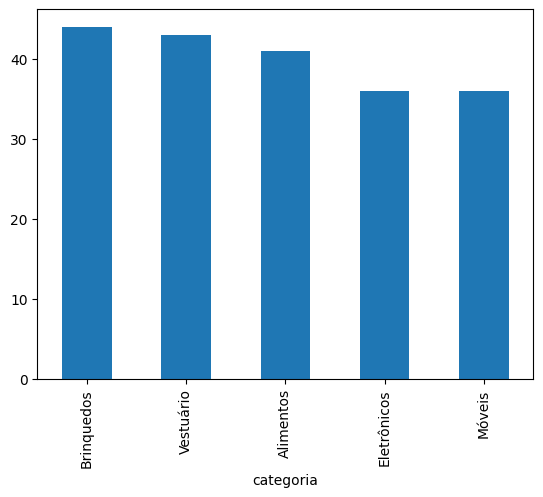

In [34]:
#grafico simples de barra
df['categoria'].value_counts().plot(kind='bar')
plt.show()

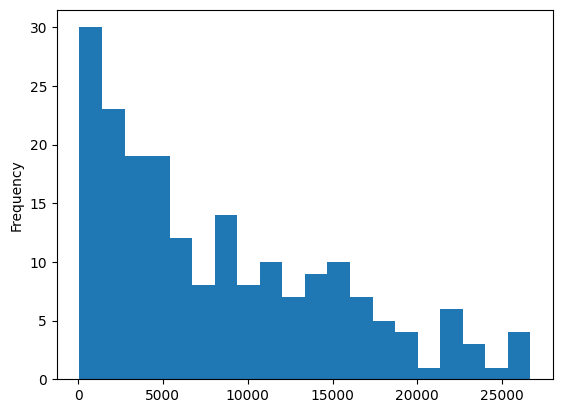

In [36]:
#histograma de distribuicao dos valores de vendas 'total_venda'
df['total_venda'].plot(kind='hist', bins=20)
plt.show()



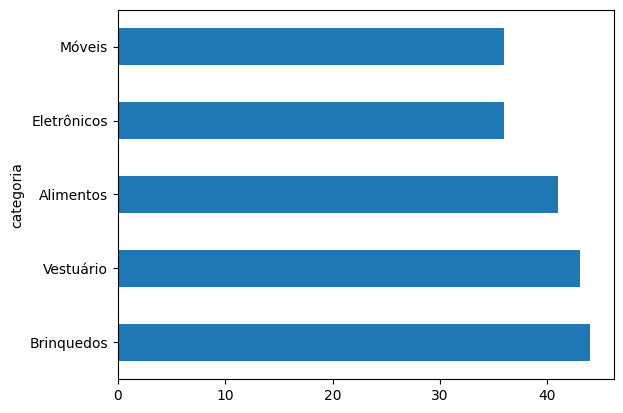

In [37]:
#grafico de barras horizontais com o total
df['categoria'].value_counts().plot(kind='barh')
plt.show()

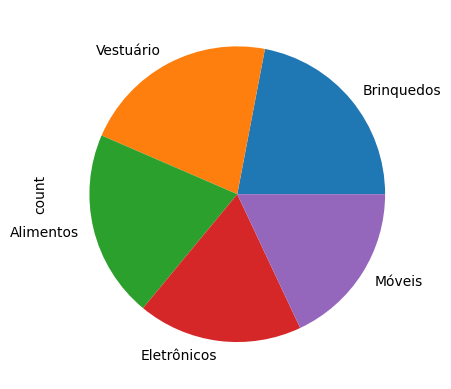

In [38]:
#grafico de barras horizontais com o total
df['categoria'].value_counts().plot(kind='pie')
plt.show()

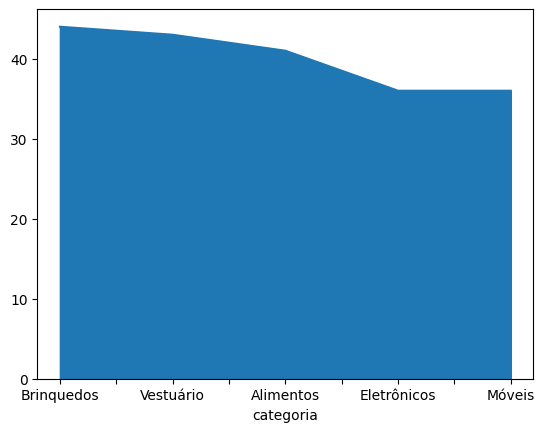

In [39]:
#grafico de barras horizontais com o total
df['categoria'].value_counts().plot(kind='area')
plt.show()

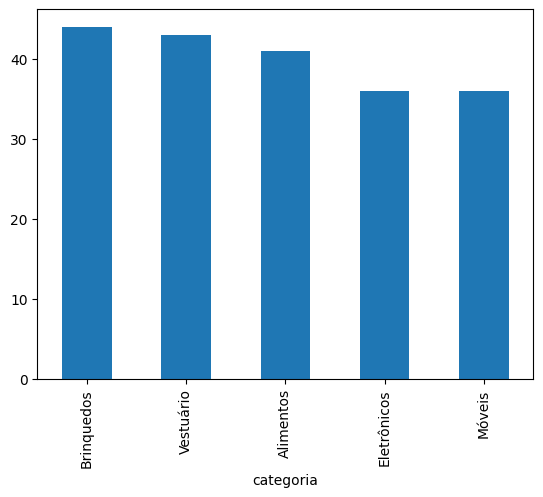

In [41]:
#grafico de barras horizontais com o total
df['categoria'].value_counts().plot(kind='bar')
plt.show()

Criar uma coluna nova VIP ou NAO VIP

In [42]:
#criar uma nova coluna STATUS do CLIENTE
df['STATUS'] = np.where(df['total_venda'] > 1000, 'VIP', 'NAO VIP')
print(df['STATUS'])

0          VIP
1          VIP
2          VIP
3          VIP
4          VIP
        ...   
195        VIP
196    NAO VIP
197        VIP
198        VIP
199        VIP
Name: STATUS, Length: 200, dtype: object


In [43]:
#vendo o head do data set
print(df.head())

   data_venda          nome_cliente estado    nome_produto    categoria  \
0  2025-05-11   Dra, Mariana da Paz     BA           Leite    Alimentos   
1  2025-03-14       Marcela Rezende     BA          Feijão    Alimentos   
2  2025-04-18    Srta, Brenda Cunha     BA   Quebra-Cabeça   Brinquedos   
3  2025-02-09  Maria Clara Caldeira     BA  Fone de Ouvido  Eletrônicos   
4  2025-04-10   João Felipe Cardoso     BA        Carrinho   Brinquedos   

   quantidade  preco_unitario  total_venda  quantidade_estoque  \
0           9         1610.73     14496.57                 116   
1           7         2406.94     16848.58                 131   
2           1         2192.52      2192.52                 224   
3           2         2008.93      4017.86                 201   
4           8          624.63      4997.04                 170   

  localizacao_estoque   ano  mes  dia  dia da semana STATUS  
0            C3-A2-B2  2025    5   11              1    VIP  
1            B2-A1-C2  2025 

trabalhando com datas

In [44]:
#garantir que as informacoens de data estao no formato datetime
df['data_venda'] = pd.to_datetime(df['data_venda'])

In [45]:
#extrair as informacoes de data
df['ano'] = df['data_venda'].dt.year
df['mes'] = df['data_venda'].dt.month
df['dia'] = df['data_venda'].dt.day
df['dia da semana'] = df['data_venda'].dt.day

Analise de oportunidades

In [46]:
#qual o total de vendas?
print(df['total_venda'].sum())

1682529.3800000001


In [47]:
#qual a media de vendas?
print(df['total_venda'].mean())

8412.6469


In [48]:
#qual a categoria vende mais?
print(df.groupby('categoria')['total_venda'].sum())

categoria
Alimentos      378777.27
Brinquedos     331006.07
Eletrônicos    322217.60
Móveis         286853.41
Vestuário      363675.03
Name: total_venda, dtype: float64


In [49]:
#maior venda individual?
print(df.sort_values('total_venda', ascending=False).head(1))

   data_venda     nome_cliente estado nome_produto  categoria  quantidade  \
10 2025-03-07  Gabriel Azevedo     BA      Jaqueta  Vestuário           9   

    preco_unitario  total_venda  quantidade_estoque localizacao_estoque   ano  \
10         2962.51     26662.59                  53            D1-A2-B1  2025   

    mes  dia  dia da semana STATUS  
10    3    7              7    VIP  


analise final

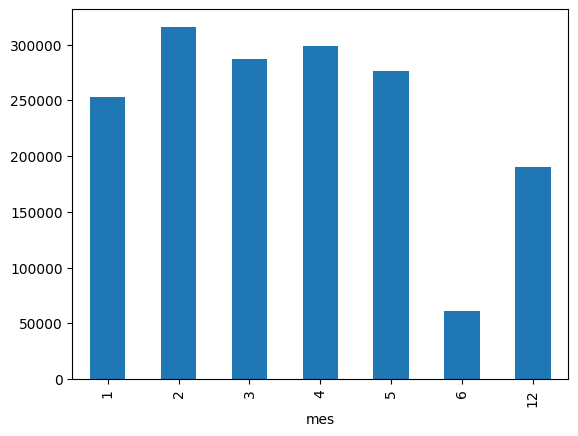

In [50]:
#grafico de vendas totais por mes
df.groupby('mes')['total_venda'].sum().plot(kind='bar')
plt.show()

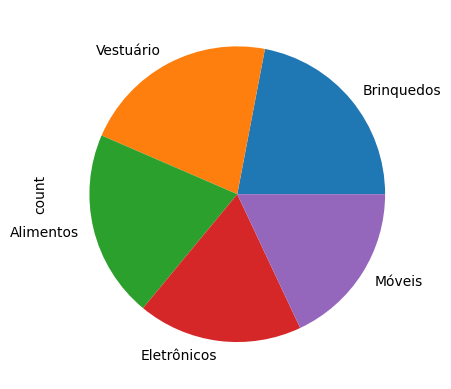

In [51]:
#grafico de pizza do percentual de vendas por categoria
df['categoria'].value_counts().plot(kind='pie')
plt.show()

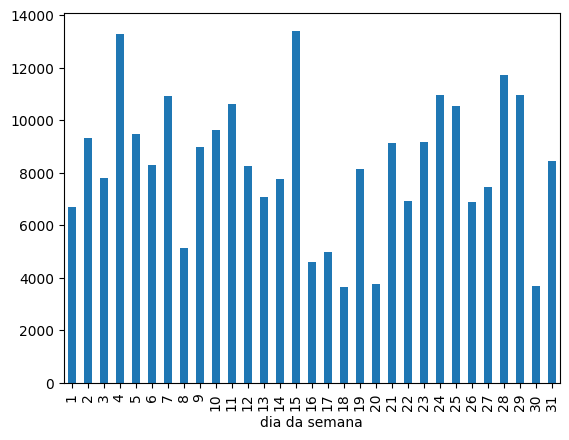

In [52]:
#grafico de vendas medias por dia da semana
df.groupby('dia da semana')['total_venda'].mean().plot(kind='bar')
plt.show()

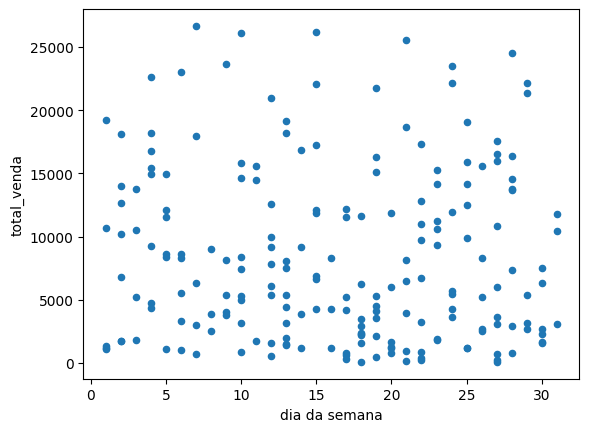

In [53]:
#grafico de dispersao do dia da semana com o total de venda
df.plot(x='dia da semana', y='total_venda', kind='scatter')
plt.show()

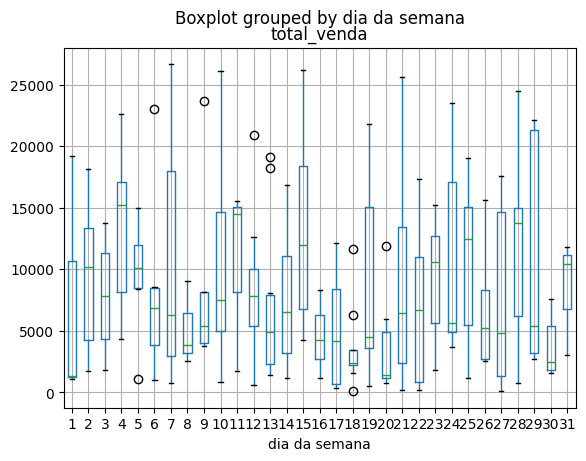

In [54]:
#boxplot da distribuicao de vendas por dia
df.boxplot(column='total_venda', by='dia da semana')
plt.show()

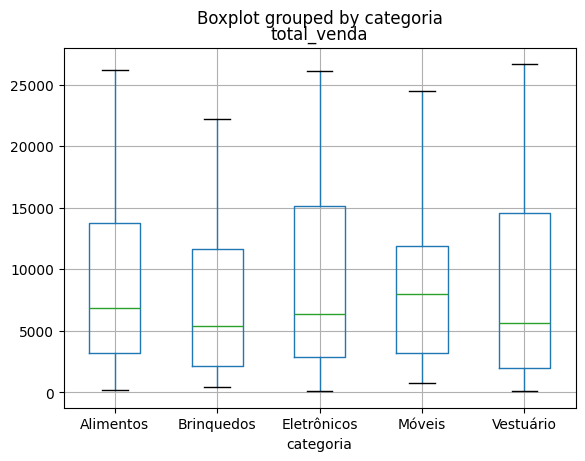

In [55]:
#boxplot total de vendas por categoria
df.boxplot(column='total_venda', by='categoria')
plt.show()

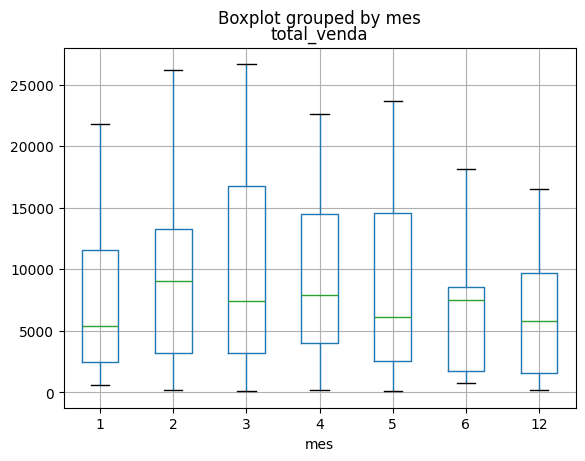

In [56]:
#boxplot total de vendas por mes
df.boxplot(column='total_venda', by='mes')
plt.show()

In [57]:
#comparando o valor medio de vendas entre vip e nao vip
print(df.groupby('STATUS')['total_venda'].mean())

STATUS
NAO VIP     534.383333
VIP        9191.815824
Name: total_venda, dtype: float64


In [58]:
#comparando o valor total vendido por status
print(df.groupby('STATUS')['total_venda'].sum())

STATUS
NAO VIP       9618.90
VIP        1672910.48
Name: total_venda, dtype: float64


In [59]:
#comparando as compras dos vips e nao vips por categoria
print(df.groupby(['STATUS', 'categoria'])['total_venda'].sum())

STATUS   categoria  
NAO VIP  Alimentos        1225.15
         Brinquedos       2359.33
         Eletrônicos      2610.03
         Móveis           1533.56
         Vestuário        1890.83
VIP      Alimentos      377552.12
         Brinquedos     328646.74
         Eletrônicos    319607.57
         Móveis         285319.85
         Vestuário      361784.20
Name: total_venda, dtype: float64


conclusao da estrategia

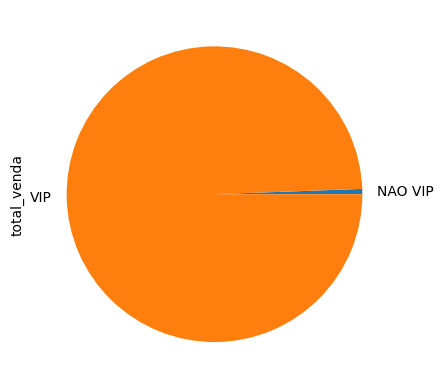

In [60]:
#grafico de pizza comparando o total de vendas de vips e nao vips
df.groupby('STATUS')['total_venda'].sum().plot(kind='pie')
plt.show()

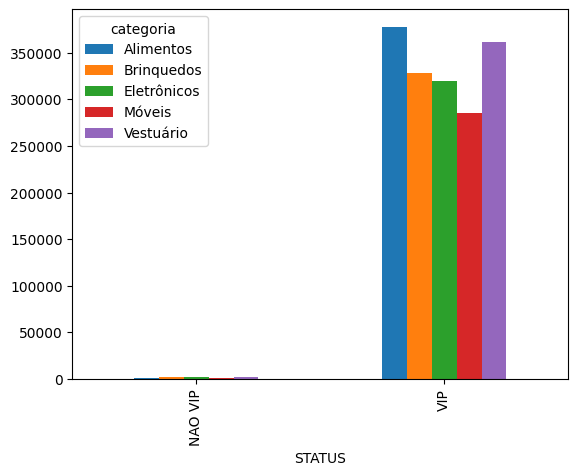

In [61]:
#gerar um grafico de barras comparando as compras dos vips e nao vips por categoria
df.groupby(['STATUS', 'categoria'])['total_venda'].sum().unstack().plot(kind='bar')
plt.show()